# Fase 2 — Entendimento dos Dados

Base: `demanda.csv`. Objetivo: descobrir problemas, sem corrigir nada (correção é Fase 3).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.dados import carregar_demanda

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 1. Carga e visão geral

In [2]:
demanda = carregar_demanda()

data_min, data_max = demanda["data"].min(), demanda["data"].max()
print(f"Linhas:              {len(demanda):,}")
print(f"Produtos distintos:  {demanda['produto'].nunique()}")
print(f"Data mínima:         {data_min.date()}")
print(f"Data máxima:         {data_max.date()}")
print(f"Dias no calendário:  {(data_max - data_min).days + 1}")
print(f"Datas distintas:     {demanda['data'].nunique()}")

Linhas:              30,849
Produtos distintos:  30
Data mínima:         2017-01-02
Data máxima:         2019-10-31
Dias no calendário:  1033
Datas distintas:     1033


## 2. Primeiras linhas e tipos

In [3]:
print(demanda.head(10).to_string())
print()
print(demanda.dtypes.to_string())

  produto       data  unidades  preco_medio  pct_lojas_promo  estoque_total  lojas_ativas
0   P0017 2017-01-02      89.0         1.49           0.0000         2023.0            75
1   P0017 2017-01-03      74.0         1.49           0.0000         2040.0            76
2   P0017 2017-01-04     114.0         1.49           0.0000         1993.0            77
3   P0017 2017-01-05     175.0         1.49           0.9221         2111.0            77
4   P0017 2017-01-06     118.0         1.49           0.9211         2080.0            76
5   P0017 2017-01-07     160.0         1.49           0.9067         1990.0            75
6   P0017 2017-01-08     185.0         1.49           0.9067         1867.0            75
7   P0017 2017-01-09     133.0         1.49           0.9178         1872.0            73
8   P0017 2017-01-10     116.0         1.49           0.9041         1918.0            73
9   P0017 2017-01-11     227.0         1.49           0.8947         1947.0            76

produto  

## 3. Dicionário de dados

Faixas observadas de cada coluna, para sustentar a interpretação.

In [4]:
print(demanda.describe().T.round(4).to_string())
print()
print("Linhas duplicadas em (produto, data):", demanda.duplicated(["produto", "data"]).sum())

                   count                           mean                  min                  25%                  50%                  75%                  max          std
data               30849  2018-05-31 06:59:16.238451968  2017-01-02 00:00:00  2017-09-16 00:00:00  2018-05-31 00:00:00  2019-02-12 00:00:00  2019-10-31 00:00:00          NaN
unidades         30849.0                      149.50705                  0.0                 55.0                 86.0                154.0              43882.0   402.708105
preco_medio      30840.0                       3.764655                 0.25                  1.0                  2.6                 3.95                 37.5     5.301444
pct_lojas_promo  30849.0                       0.086712                  0.0                  0.0                  0.0                  0.0                  1.0     0.270411
estoque_total    30849.0                    3442.948361                  0.0               1906.0               2787.0            

In [5]:
dicionario = pd.DataFrame([
    ("produto", "texto", "-", "Código do SKU", "chave"),
    ("data", "datetime", "dia", "Dia de referência do registro", "chave"),
    ("unidades", "decimal", "unidades/dia", "Unidades vendidas na rede (soma das lojas) no dia", "ALVO"),
    ("preco_medio", "decimal", "R$/unidade", "Preço praticado no dia, média das lojas", "explicativa"),
    ("pct_lojas_promo", "decimal", "fração 0–1", "Fração das lojas ativas com o item em promoção no dia", "explicativa"),
    ("estoque_total", "decimal", "unidades", "Saldo de estoque somado nas lojas (não é o estoque do CD)", "explicativa"),
    ("lojas_ativas", "inteiro", "nº de lojas", "Lojas que comercializaram o item no dia", "explicativa"),
], columns=["coluna", "tipo", "unidade", "significado", "papel"])
print(dicionario.to_string(index=False))

         coluna     tipo      unidade                                               significado       papel
        produto    texto            -                                             Código do SKU       chave
           data datetime          dia                             Dia de referência do registro       chave
       unidades  decimal unidades/dia         Unidades vendidas na rede (soma das lojas) no dia        ALVO
    preco_medio  decimal   R$/unidade                   Preço praticado no dia, média das lojas explicativa
pct_lojas_promo  decimal   fração 0–1     Fração das lojas ativas com o item em promoção no dia explicativa
  estoque_total  decimal     unidades Saldo de estoque somado nas lojas (não é o estoque do CD) explicativa
   lojas_ativas  inteiro  nº de lojas                   Lojas que comercializaram o item no dia explicativa


## 4. Valores nulos

In [6]:
nulos = demanda.isna().sum()
tabela_nulos = pd.DataFrame({
    "qtd_nulos": nulos,
    "pct_nulos": (nulos / len(demanda) * 100).round(3),
}).query("qtd_nulos > 0")
print(tabela_nulos.to_string())
print()
print(demanda.loc[demanda.isna().any(axis=1)].to_string())

             qtd_nulos  pct_nulos
preco_medio          9      0.029

      produto       data  unidades  preco_medio  pct_lojas_promo  estoque_total  lojas_ativas
11363   P0198 2017-01-02      26.0          NaN              0.0            0.0             4
11364   P0198 2017-01-03       6.0          NaN              0.0            0.0             3
11365   P0198 2017-01-04       5.0          NaN              0.0            0.0             2
11366   P0198 2017-01-05       6.0          NaN              0.0            0.0             1
11367   P0198 2017-01-14      12.0          NaN              0.0            0.0             2
11368   P0198 2017-01-15      51.0          NaN              0.0            0.0             6
11369   P0198 2017-01-16      81.0          NaN              0.0            0.0             6
11370   P0198 2017-01-17      84.0          NaN              0.0            0.0             9
11371   P0198 2017-01-18      72.0          NaN              0.0            0.0      

## 5. Continuidade da série de cada produto

In [7]:
continuidade = demanda.groupby("produto")["data"].agg(primeira="min", ultima="max", dias_presentes="nunique")
continuidade["dias_esperados"] = (continuidade["ultima"] - continuidade["primeira"]).dt.days + 1
continuidade["dias_faltando"] = continuidade["dias_esperados"] - continuidade["dias_presentes"]

print("Produtos que não cobrem o período completo da base:")
print(continuidade.query("primeira != @data_min or ultima != @data_max").to_string())
print()
print("Produtos com dias faltando entre a primeira e a última data:")
print(continuidade.query("dias_faltando > 0").to_string())

Produtos que não cobrem o período completo da base:
Empty DataFrame
Columns: [primeira, ultima, dias_presentes, dias_esperados, dias_faltando]
Index: []

Produtos com dias faltando entre a primeira e a última data:
          primeira     ultima  dias_presentes  dias_esperados  dias_faltando
produto                                                                     
P0198   2017-01-02 2019-10-31            1025            1033              8
P0438   2017-01-02 2019-10-31             900            1033            133


In [8]:
def intervalos_faltantes(serie_datas):
    calendario = pd.date_range(serie_datas.min(), serie_datas.max(), freq="D")
    faltantes = calendario.difference(serie_datas)
    if faltantes.empty:
        return pd.DataFrame(columns=["inicio", "fim", "dias"])
    grupo = (faltantes.to_series().diff().dt.days != 1).cumsum()
    blocos = faltantes.to_series().groupby(grupo.values).agg(["min", "max", "count"])
    blocos.columns = ["inicio", "fim", "dias"]
    return blocos.reset_index(drop=True)

for produto in continuidade.query("dias_faltando > 0").index:
    print(f"--- {produto}")
    print(intervalos_faltantes(demanda.loc[demanda["produto"] == produto, "data"]).to_string(index=False))

--- P0198
    inicio        fim  dias
2017-01-06 2017-01-13     8
--- P0438
    inicio        fim  dias
2019-05-10 2019-05-16     7
2019-06-06 2019-10-09   126


## 6. `estoque_total`: saldo de início ou de fim de dia?

Teste em `demanda_por_loja.csv` (P0131): se o saldo fosse de início de dia, estoque zero impediria venda no mesmo dia.

In [9]:
from src.dados import carregar_demanda_loja

demanda_loja = carregar_demanda_loja()
print(f"Linhas: {len(demanda_loja):,} | lojas: {demanda_loja['loja'].nunique()} | produto: {demanda_loja['produto'].unique()}")

zerados = demanda_loja[demanda_loja["estoque_fim_dia"] == 0]
com_venda = (zerados["unidades"] > 0).sum()
print(f"Linhas com estoque_fim_dia == 0:          {len(zerados):,}")
print(f"  dessas, com unidades > 0 no mesmo dia:  {com_venda:,} ({com_venda / len(zerados):.2%})")
print(f"  dessas, com unidades == 0:              {len(zerados) - com_venda:,}")
print()
print(zerados.sample(10, random_state=SEED).sort_values(["loja", "data"]).to_string(index=False))

Linhas: 130,843 | lojas: 144 | produto: ['P0131']
Linhas com estoque_fim_dia == 0:          1,333
  dessas, com unidades > 0 no mesmo dia:  1,333 (100.00%)
  dessas, com unidades == 0:              0

produto  loja       data  unidades  estoque_fim_dia  preco  em_promo
  P0131 S0029 2017-01-05       1.0              0.0    NaN         0
  P0131 S0029 2017-01-08       1.0              0.0    NaN         0
  P0131 S0029 2017-04-05       1.0              0.0    NaN         0
  P0131 S0029 2017-05-05       1.0              0.0    NaN         0
  P0131 S0048 2017-04-28       1.0              0.0    NaN         0
  P0131 S0058 2019-02-01       2.0              0.0    3.0         0
  P0131 S0081 2017-05-16       2.0              0.0    NaN         0
  P0131 S0108 2017-12-31       3.0              0.0    2.5         0
  P0131 S0112 2017-06-12       1.0              0.0    NaN         0
  P0131 S0128 2017-04-01       5.0              0.0    NaN         0


Contexto de uma ruptura: dias ao redor de um zeramento numa loja.

In [10]:
exemplo = zerados.iloc[0]
janela = demanda_loja[(demanda_loja["loja"] == exemplo["loja"])
                      & demanda_loja["data"].between(exemplo["data"] - pd.Timedelta(days=4), exemplo["data"] + pd.Timedelta(days=4))]
print(janela.to_string(index=False))

produto  loja       data  unidades  estoque_fim_dia  preco  em_promo
  P0131 S0003 2018-02-07       4.0              7.0    2.5         0
  P0131 S0003 2018-02-08       3.0              4.0    2.5         0
  P0131 S0003 2018-02-09       0.0              4.0    2.5         0
  P0131 S0003 2018-02-10       2.0              2.0    2.5         0
  P0131 S0003 2018-02-11       2.0              0.0    2.5         0
  P0131 S0003 2018-02-12       2.0              0.0    2.5         0
  P0131 S0003 2018-02-13       0.0             34.0    2.5         0
  P0131 S0003 2018-02-14       2.0             32.0    2.5         0
  P0131 S0003 2018-02-15       0.0             32.0    2.5         0


A conclusão da base por loja só vale para `estoque_total` se ele for a soma de `estoque_fim_dia` das lojas.

In [11]:
soma_lojas = demanda_loja.groupby("data")[["unidades", "estoque_fim_dia"]].sum()
p0131 = demanda[demanda["produto"] == "P0131"].set_index("data")[["unidades", "estoque_total"]]
comparacao = p0131.join(soma_lojas, rsuffix="_lojas")

print(f"Dias comparados: {len(comparacao)}")
print(f"unidades == soma das lojas:             {(comparacao['unidades'] == comparacao['unidades_lojas']).mean():.2%}")
print(f"estoque_total == soma estoque_fim_dia:  {(comparacao['estoque_total'] == comparacao['estoque_fim_dia']).mean():.2%}")
print(f"Maior diferença absoluta no estoque:    {(comparacao['estoque_total'] - comparacao['estoque_fim_dia']).abs().max()}")

Dias comparados: 1033
unidades == soma das lojas:             100.00%
estoque_total == soma estoque_fim_dia:  100.00%
Maior diferença absoluta no estoque:    0.0


Frequência de ruptura no nível loja (dias em que a loja terminou zerada).

In [12]:
pct_dias_zerados = (demanda_loja["estoque_fim_dia"] == 0).mean()
dias_zerados_rede = demanda_loja.assign(zerou=demanda_loja["estoque_fim_dia"] == 0).groupby("data")["zerou"].sum()
print(f"Loja-dias com estoque_fim_dia == 0: {pct_dias_zerados:.2%}")
print(f"Lojas zeradas por dia na rede: média {dias_zerados_rede.mean():.2f} | máximo {dias_zerados_rede.max()}")
print(f"Dias com ao menos uma loja zerada: {(dias_zerados_rede > 0).mean():.2%}")

Loja-dias com estoque_fim_dia == 0: 1.02%
Lojas zeradas por dia na rede: média 1.29 | máximo 12
Dias com ao menos uma loja zerada: 39.69%


## 7. Grão da previsão: loja × dia ou rede × dia (P0131)

In [13]:
venda_loja = demanda_loja["unidades"]
venda_rede = demanda.loc[demanda["produto"] == "P0131"].set_index("data")["unidades"]

resumo_grao = pd.DataFrame({
    "loja × dia": [venda_loja.mean(), venda_loja.median(), (venda_loja == 0).mean() * 100, venda_loja.std() / venda_loja.mean()],
    "rede × dia": [venda_rede.mean(), venda_rede.median(), (venda_rede == 0).mean() * 100, venda_rede.std() / venda_rede.mean()],
}, index=["média (un/dia)", "mediana (un/dia)", "% dias com venda zero", "coef. de variação"]).round(2)
print(resumo_grao.to_string())

zeros_por_loja = demanda_loja.groupby("loja")["unidades"].apply(lambda s: (s == 0).mean() * 100)
print()
print("% de dias com venda zero, distribuição entre as 144 lojas:")
print(zeros_por_loja.describe().round(2).to_string())

                       loja × dia  rede × dia
média (un/dia)               1.64      208.06
mediana (un/dia)             0.00      190.00
% dias com venda zero       51.25        0.00
coef. de variação            2.70        0.51

% de dias com venda zero, distribuição entre as 144 lojas:
count    144.00
mean      51.36
std       22.94
min        0.39
25%       35.84
50%       54.68
75%       68.11
max       93.92


Loja sorteada (SEED=42): S0118
  média 0.87 | mediana 0 | dias com zero 51.60%


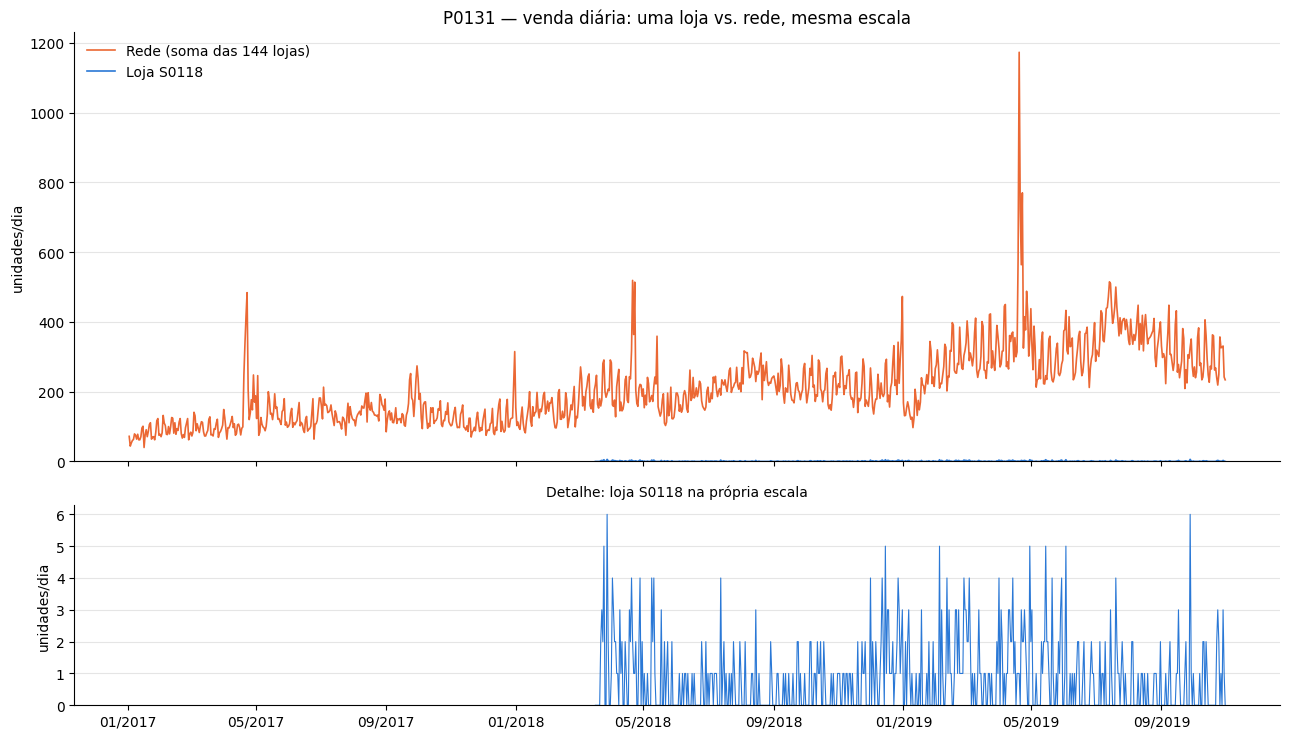

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

COR_LOJA, COR_REDE = "#2a78d6", "#eb6834"
CAMINHO_FIGURAS = Path.cwd().parent / "relatorios" / "figuras"

loja_exemplo = demanda_loja["loja"].drop_duplicates().sample(1, random_state=SEED).iloc[0]
serie_loja = demanda_loja.loc[demanda_loja["loja"] == loja_exemplo].set_index("data")["unidades"]
print(f"Loja sorteada (SEED={SEED}): {loja_exemplo}")
print(f"  média {serie_loja.mean():.2f} | mediana {serie_loja.median():.0f} | dias com zero {(serie_loja == 0).mean():.2%}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
ax1.plot(venda_rede.index, venda_rede.values, color=COR_REDE, lw=1.2, label="Rede (soma das 144 lojas)")
ax1.plot(serie_loja.index, serie_loja.values, color=COR_LOJA, lw=1.2, label=f"Loja {loja_exemplo}")
ax1.set_title("P0131 — venda diária: uma loja vs. rede, mesma escala")
ax1.set_ylabel("unidades/dia")
ax1.legend(loc="upper left", frameon=False)

ax2.plot(serie_loja.index, serie_loja.values, color=COR_LOJA, lw=0.8)
ax2.set_title(f"Detalhe: loja {loja_exemplo} na própria escala", fontsize=10)
ax2.set_ylabel("unidades/dia")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))

for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)

fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_grao_loja_vs_rede_P0131.png", dpi=130)
plt.show()

**Decisão:** grão produto × dia na rede, base `demanda.csv`. O `demanda_por_loja.csv` sai do projeto a partir daqui (registro em `relatorios/decisoes.md`).

## 8. Série do P0131

In [15]:
PRODUTO = "P0131"

serie_p0131 = (demanda.loc[demanda["produto"] == PRODUTO]
               .set_index("data")
               .drop(columns="produto")
               .asfreq("D"))

print(f"Frequência do índice: {serie_p0131.index.freqstr}")
print(f"Dias na série:        {len(serie_p0131)}")
print(f"De {serie_p0131.index.min().date()} até {serie_p0131.index.max().date()}")
print()
print(f"Dias vazios (sem registro):  {serie_p0131['unidades'].isna().sum()}")
print(f"Dias com venda zero:         {(serie_p0131['unidades'] == 0).sum()}")
print()
print(f"Venda média por dia:         {serie_p0131['unidades'].mean():.2f} unidades")
print(f"Preço médio (média diária):  R$ {serie_p0131['preco_medio'].mean():.4f}")
print(f"Preço mínimo / máximo:       R$ {serie_p0131['preco_medio'].min():.2f} / R$ {serie_p0131['preco_medio'].max():.2f}")

Frequência do índice: D
Dias na série:        1033
De 2017-01-02 até 2019-10-31

Dias vazios (sem registro):  0
Dias com venda zero:         0

Venda média por dia:         208.06 unidades
Preço médio (média diária):  R$ 2.5870
Preço mínimo / máximo:       R$ 1.82 / R$ 3.25


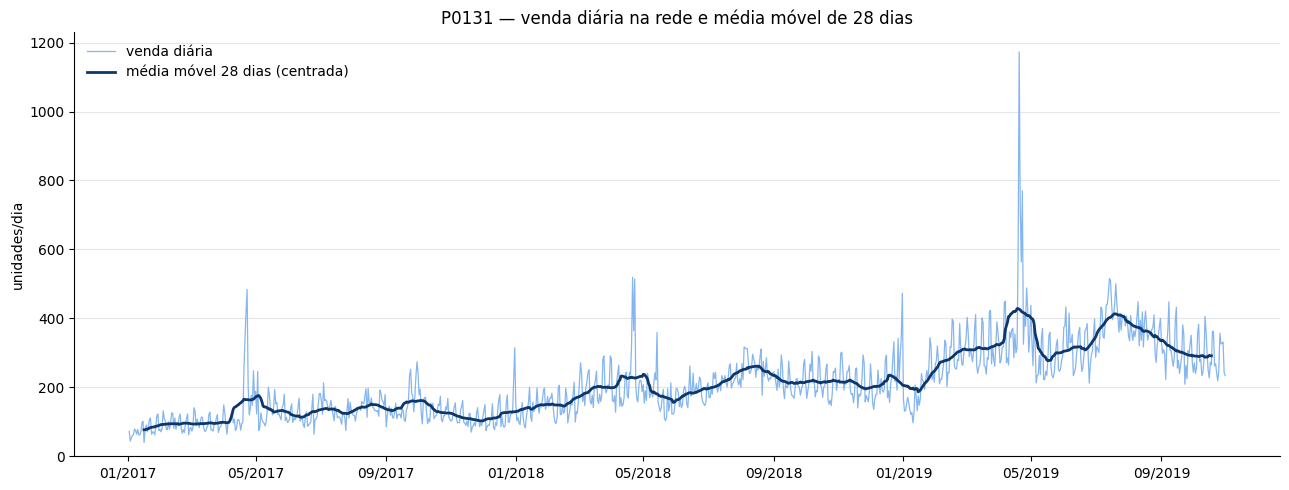

Venda média diária por trimestre:
data
2017-03-31     88.6
2017-06-30    134.8
2017-09-30    143.3
2017-12-31    123.4
2018-03-31    162.6
2018-06-30    194.7
2018-09-30    230.3
2018-12-31    219.6
2019-03-31    264.4
2019-06-30    339.5
2019-09-30    357.5
2019-12-31    287.5
Freq: QE-DEC


In [16]:
media_movel_28 = serie_p0131["unidades"].rolling(28, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie_p0131.index, serie_p0131["unidades"], color="#86b6ef", lw=0.9, label="venda diária")
ax.plot(media_movel_28.index, media_movel_28, color="#0d366b", lw=2, label="média móvel 28 dias (centrada)")
ax.set_title(f"{PRODUTO} — venda diária na rede e média móvel de 28 dias")
ax.set_ylabel("unidades/dia")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_P0131_venda_media_movel_28.png", dpi=130)
plt.show()

trimestral = serie_p0131["unidades"].resample("QE").mean().round(1)
print("Venda média diária por trimestre:")
print(trimestral.to_string())

## 9. Ciclo semanal do P0131

Venda média por dia da semana:
         media_unidades  indice_vs_media_geral  n_dias
Segunda          191.14                  0.919     148
Terça            185.02                  0.889     148
Quarta           183.00                  0.880     148
Quinta           189.36                  0.910     148
Sexta            205.10                  0.986     147
Sábado           253.44                  1.218     147
Domingo          249.92                  1.201     147

Média geral diária: 208.06


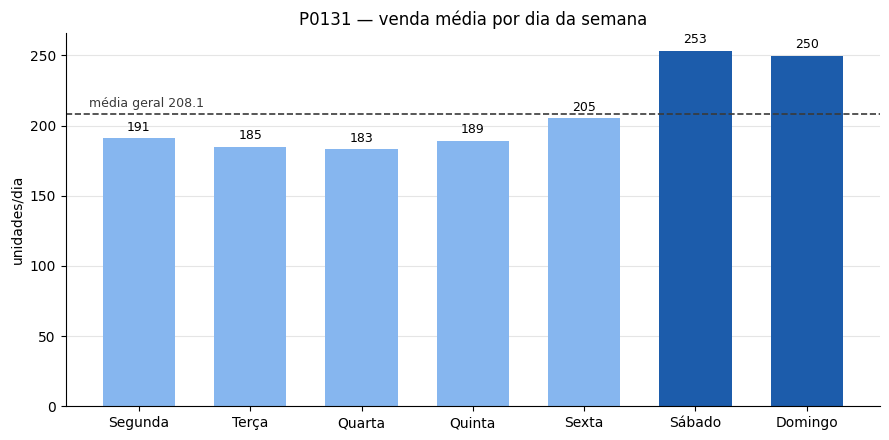

In [17]:
NOMES_DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

venda = serie_p0131["unidades"]
dia_semana = venda.index.dayofweek
media_geral = venda.mean()

media_por_dia = venda.groupby(dia_semana).mean()
media_por_dia.index = NOMES_DIAS
print("Venda média por dia da semana:")
print(pd.DataFrame({"media_unidades": media_por_dia.round(2),
                    "indice_vs_media_geral": (media_por_dia / media_geral).round(3),
                    "n_dias": venda.groupby(dia_semana).size().values}).to_string())
print(f"\nMédia geral diária: {media_geral:.2f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#86b6ef"] * 5 + ["#1c5cab"] * 2
ax.bar(media_por_dia.index, media_por_dia.values, color=cores, width=0.65)
ax.axhline(media_geral, color="#3a3a3a", lw=1.2, ls="--")
ax.text(-0.45, media_geral + 3, f"média geral {media_geral:.1f}", ha="left", va="bottom", fontsize=9, color="#3a3a3a")
for i, v in enumerate(media_por_dia.values):
    ax.text(i, v + 3, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
ax.set_title(f"{PRODUTO} — venda média por dia da semana")
ax.set_ylabel("unidades/dia")
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_P0131_media_dia_semana.png", dpi=130)
plt.show()

In [18]:
fim_de_semana = dia_semana >= 5
media_util = venda[~fim_de_semana].mean()
media_fds = venda[fim_de_semana].mean()
print(f"Média dias úteis (seg–sex): {media_util:.2f}")
print(f"Média fim de semana (sáb–dom): {media_fds:.2f}")
print(f"Razão fim de semana / dia útil: {media_fds / media_util:.3f}")

# checagem livre de tendência: cada dia dividido pela média móvel centrada de 28 dias
indice_sazonal = (venda / media_movel_28).groupby(dia_semana).mean()
indice_sazonal.index = NOMES_DIAS
print("\nÍndice dia / média móvel 28d (remove o efeito da tendência):")
print(indice_sazonal.round(3).to_string())

semanas = pd.DataFrame({"venda": venda, "fds": fim_de_semana}, index=venda.index)
por_semana = semanas.groupby([semanas.index.to_period("W-SUN"), "fds"])["venda"].mean().unstack()
por_semana = por_semana.dropna()
print(f"\nSemanas completas comparadas: {len(por_semana)}")
print(f"Semanas em que o fim de semana vendeu mais que a média dos dias úteis: {(por_semana[True] > por_semana[False]).mean():.2%}")

Média dias úteis (seg–sex): 190.71
Média fim de semana (sáb–dom): 251.68
Razão fim de semana / dia útil: 1.320

Índice dia / média móvel 28d (remove o efeito da tendência):
Segunda    0.907
Terça      0.878
Quarta     0.881
Quinta     0.907
Sexta      0.990
Sábado     1.213
Domingo    1.217

Semanas completas comparadas: 147
Semanas em que o fim de semana vendeu mais que a média dos dias úteis: 93.20%


## 10. Dá para investigar ciclo anual?

In [19]:
anos = venda.index.year
print(f"Histórico: {len(venda)} dias = {len(venda) / 365.25:.2f} anos")
print("Dias por ano:", venda.groupby(anos).size().to_dict())

ocorrencias_mes = pd.Series(venda.index.to_period("M")).drop_duplicates().dt.month.value_counts().sort_index()
ocorrencias_mes.index = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
print("\nQuantas vezes cada mês aparece na base:")
print(ocorrencias_mes.to_string())

print("\nVenda média diária por mês e ano:")
print(venda.groupby([anos, venda.index.month]).mean().unstack(0).round(1).to_string())

Histórico: 1033 dias = 2.83 anos
Dias por ano: {2017: 364, 2018: 365, 2019: 304}

Quantas vezes cada mês aparece na base:
jan    3
fev    3
mar    3
abr    3
mai    3
jun    3
jul    3
ago    3
set    3
out    3
nov    2
dez    2

Venda média diária por mês e ano:
data   2017   2018   2019
data                     
1      76.8  138.5  192.0
2      94.1  145.1  285.6
3      94.9  202.5  317.5
4     153.6  226.3  414.0
5     133.3  174.5  284.7
6     117.4  183.9  321.6
7     135.2  216.5  401.5
8     148.0  258.3  363.6
9     146.9  215.8  305.7
10    137.4  213.4  287.5
11    108.9  212.7    NaN
12    123.5  232.5    NaN


## 11. Decomposição STL (período 7, robusta)

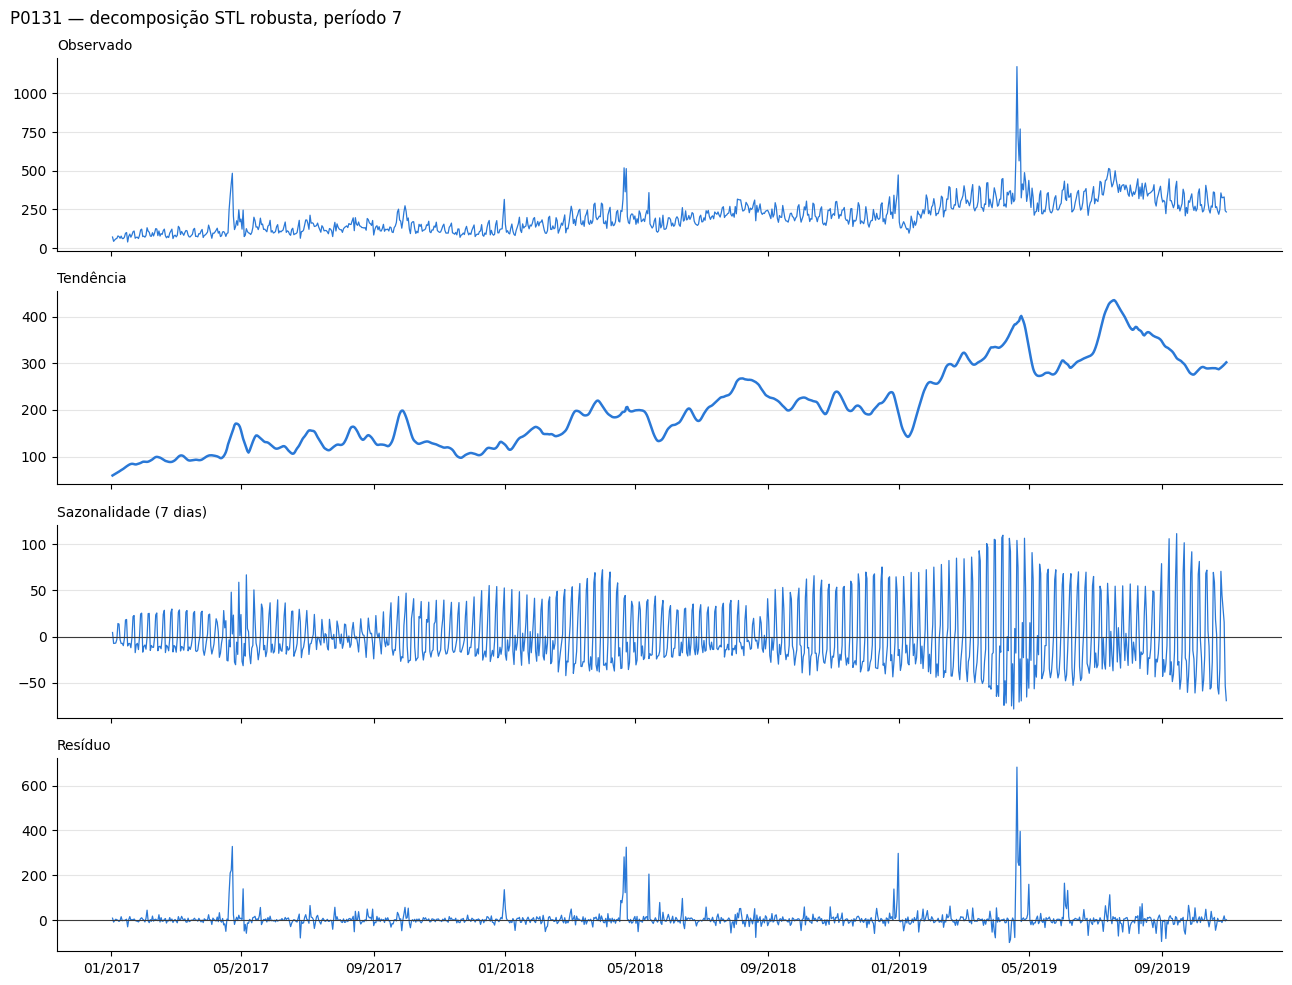

In [20]:
from statsmodels.tsa.seasonal import STL

stl = STL(venda, period=7, robust=True).fit()
tendencia, sazonal, residuo = stl.trend, stl.seasonal, stl.resid

fig, eixos = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
paineis = [(venda, "Observado"), (tendencia, "Tendência"), (sazonal, "Sazonalidade (7 dias)"), (residuo, "Resíduo")]
for ax, (serie, titulo) in zip(eixos, paineis):
    ax.plot(serie.index, serie.values, color="#2a78d6", lw=0.9 if titulo != "Tendência" else 1.8)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
for ax in eixos[2:]:
    ax.axhline(0, color="#3a3a3a", lw=0.8)
eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.suptitle(f"{PRODUTO} — decomposição STL robusta, período 7", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_P0131_stl.png", dpi=130)
plt.show()

In [21]:
# Hyndman: F = max(0, 1 - Var(R) / Var(componente + R))
forca_tendencia = max(0, 1 - residuo.var() / (tendencia + residuo).var())
forca_sazonalidade = max(0, 1 - residuo.var() / (sazonal + residuo).var())
print(f"Força da tendência (Ft):     {forca_tendencia:.4f}")
print(f"Força da sazonalidade (Fs):  {forca_sazonalidade:.4f}")

Força da tendência (Ft):     0.8173
Força da sazonalidade (Fs):  0.3700


In [22]:
escala_robusta = 1.4826 * (residuo - residuo.median()).abs().median()
residuo_padronizado = residuo / escala_robusta

print(f"Resíduo: média {residuo.mean():.2f} | desvio-padrão {residuo.std():.2f} | escala robusta (MAD) {escala_robusta:.2f}")
print(f"Assimetria {residuo.skew():.2f} | curtose (excesso) {residuo.kurt():.2f}")
print(f"Dias com |resíduo| > 3 escalas robustas: {(residuo_padronizado.abs() > 3).sum()} de {len(residuo)} "
      f"(positivos {(residuo_padronizado > 3).sum()}, negativos {(residuo_padronizado < -3).sum()})")

abs_ordenado = residuo.abs().sort_values(ascending=False)
print(f"Participação dos 2% maiores dias na soma de |resíduo|: {abs_ordenado.head(int(len(residuo) * 0.02)).sum() / abs_ordenado.sum():.2%}")

print("\n15 maiores resíduos positivos:")
print(residuo.nlargest(15).round(1).to_string())
print("\n5 maiores resíduos negativos:")
print(residuo.nsmallest(5).round(1).to_string())

extremos = residuo_padronizado[residuo_padronizado > 3]
print("\nDias com resíduo > 3 escalas, por ano-mês:")
print(extremos.groupby(extremos.index.to_period("M")).size().to_string())

Resíduo: média 4.88 | desvio-padrão 42.74 | escala robusta (MAD) 11.96
Assimetria 7.06 | curtose (excesso) 81.42
Dias com |resíduo| > 3 escalas robustas: 102 de 1033 (positivos 66, negativos 36)
Participação dos 2% maiores dias na soma de |resíduo|: 26.63%

15 maiores resíduos positivos:
data
2019-04-20    682.8
2019-04-23    395.9
2017-04-23    328.6
2018-04-23    325.2
2018-12-31    297.7
2018-04-21    281.9
2019-04-21    258.7
2019-04-22    244.0
2017-04-22    222.7
2019-04-19    218.1
2017-04-21    209.8
2018-05-14    205.2
2019-06-03    164.6
2019-05-01    159.5
2017-05-03    139.3

5 maiores resíduos negativos:
data
2019-04-13   -100.4
2019-09-01    -95.8
2019-04-14    -87.0
2019-09-05    -82.5
2017-06-25    -80.0

Dias com resíduo > 3 escalas, por ano-mês:
data
2017-02    1
2017-04    4
2017-05    2
2017-07    2
2017-08    4
2017-09    1
2017-10    1
2017-12    2
2018-01    1
2018-03    1
2018-04    6
2018-05    2
2018-06    1
2018-07    1
2018-08    3
2018-10    2
2018-12    4


## 12. Triagem de ciclo de vida dos 30 produtos

Razão = venda média diária dos últimos 90 dias / venda média diária entre 455 e 90 dias atrás.

In [23]:
inicio_recente = data_max - pd.Timedelta(days=89)
inicio_base = data_max - pd.Timedelta(days=454)

janela_recente = demanda[demanda["data"] >= inicio_recente]
janela_base = demanda[(demanda["data"] >= inicio_base) & (demanda["data"] < inicio_recente)]
print(f"Janela recente:   {inicio_recente.date()} a {data_max.date()} ({(data_max - inicio_recente).days + 1} dias)")
print(f"Janela anterior:  {inicio_base.date()} a {(inicio_recente - pd.Timedelta(days=1)).date()} ({(inicio_recente - inicio_base).days} dias)")

triagem = pd.DataFrame({
    "media_90d": janela_recente.groupby("produto")["unidades"].mean(),
    "media_455_90d": janela_base.groupby("produto")["unidades"].mean(),
    "dias_reg_90d": janela_recente.groupby("produto").size(),
    "dias_reg_455_90d": janela_base.groupby("produto").size(),
})
triagem["razao"] = triagem["media_90d"] / triagem["media_455_90d"]
triagem = triagem.sort_values("razao")

print("\n6 menores razões:")
print(triagem.head(6).round(3).to_string())
print("\n3 maiores razões:")
print(triagem.tail(3).round(3).to_string())
print(f"\nProdutos com razão < 0,6: {(triagem['razao'] < 0.6).sum()}")
print("\nDistribuição da razão nos 30 produtos:")
print(triagem["razao"].describe().round(3).to_string())

Janela recente:   2019-08-03 a 2019-10-31 (90 dias)
Janela anterior:  2018-08-03 a 2019-08-02 (365 dias)

6 menores razões:
         media_90d  media_455_90d  dias_reg_90d  dias_reg_455_90d  razao
produto                                                                 
P0438        0.045        274.493            22               300  0.000
P0051       28.367        263.312            90               365  0.108
P0079        4.322         31.452            90               365  0.137
P0590      114.678        142.184            90               365  0.807
P0035       42.656         51.449            90               365  0.829
P0185       45.778         55.074            90               365  0.831

3 maiores razões:
         media_90d  media_455_90d  dias_reg_90d  dias_reg_455_90d  razao
produto                                                                 
P0436      147.322        110.170            90               365  1.337
P0499      191.667        138.507            90       

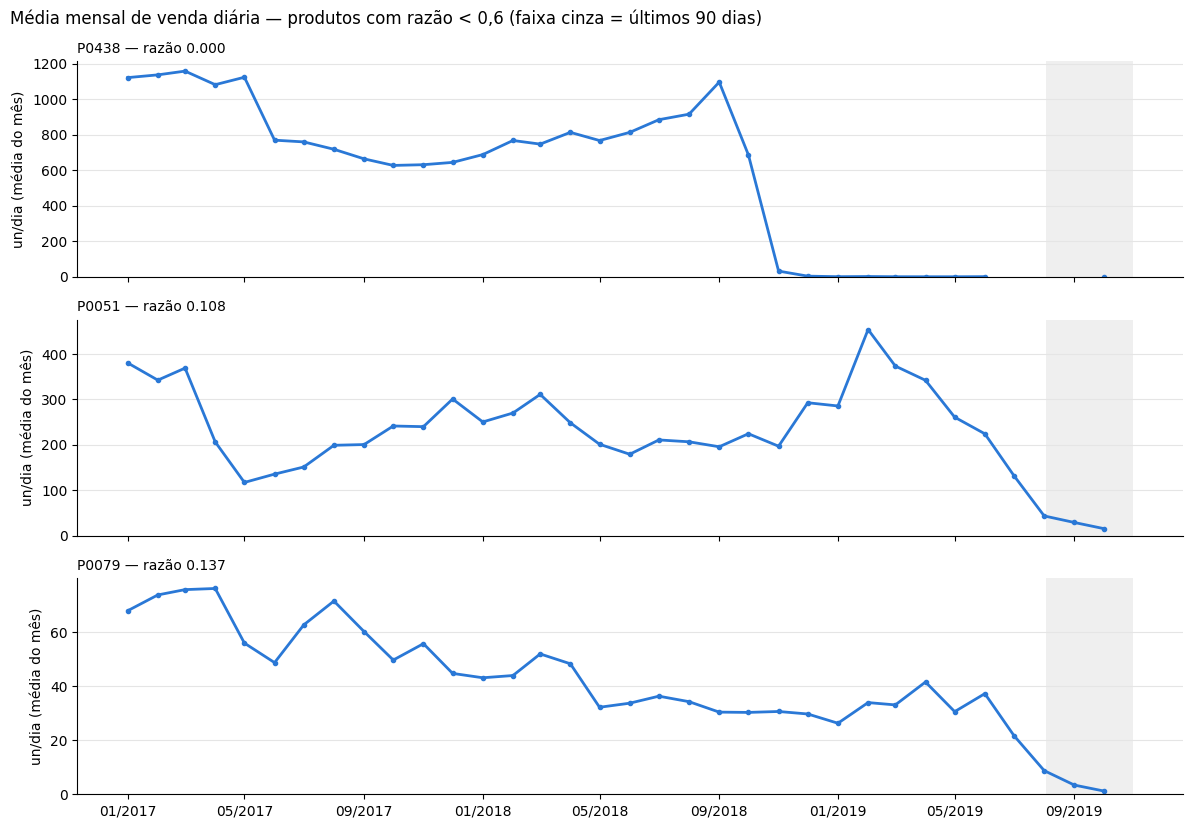

Média mensal dos últimos 8 meses:
produto     P0051  P0079  P0438
data                           
2019-03-01  373.2   33.0    0.2
2019-04-01  341.9   41.5    0.0
2019-05-01  260.6   30.5    0.0
2019-06-01  224.0   37.2    0.6
2019-07-01  131.5   21.6    NaN
2019-08-01   43.1    8.7    NaN
2019-09-01   28.7    3.4    NaN
2019-10-01   15.3    1.2    0.0

Nos últimos 90 dias:
  P0438: dias registrados 22 | dias com venda zero 21 | máximo diário 1
  P0051: dias registrados 90 | dias com venda zero 0 | máximo diário 73
  P0079: dias registrados 90 | dias com venda zero 12 | máximo diário 19


In [24]:
produtos_queda = triagem.index[triagem["razao"] < 0.6].tolist()
mensal = (demanda[demanda["produto"].isin(produtos_queda)]
          .set_index("data").groupby("produto")["unidades"].resample("MS").mean().unstack(0))

fig, eixos = plt.subplots(len(produtos_queda), 1, figsize=(12, 2.8 * len(produtos_queda)), sharex=True)
eixos = np.atleast_1d(eixos)
for ax, produto in zip(eixos, produtos_queda):
    ax.plot(mensal.index, mensal[produto], color="#2a78d6", lw=2, marker="o", ms=3)
    ax.axvspan(inicio_recente, data_max, color="#e5e5e5", alpha=0.6, lw=0)
    ax.set_title(f"{produto} — razão {triagem.loc[produto, 'razao']:.3f}", loc="left", fontsize=10)
    ax.set_ylabel("un/dia (média do mês)")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.suptitle("Média mensal de venda diária — produtos com razão < 0,6 (faixa cinza = últimos 90 dias)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_triagem_produtos_em_queda.png", dpi=130)
plt.show()

print("Média mensal dos últimos 8 meses:")
print(mensal.tail(8).round(1).to_string())
print("\nNos últimos 90 dias:")
for produto in produtos_queda:
    v = janela_recente.loc[janela_recente["produto"] == produto, "unidades"]
    print(f"  {produto}: dias registrados {len(v)} | dias com venda zero {(v == 0).sum()} | máximo diário {v.max():.0f}")

**Decisão (aplicar na Fase 3):** P0438, P0051 e P0079 saem do painel por descontinuação.

## 13. Promoção e os picos do resíduo (P0131)

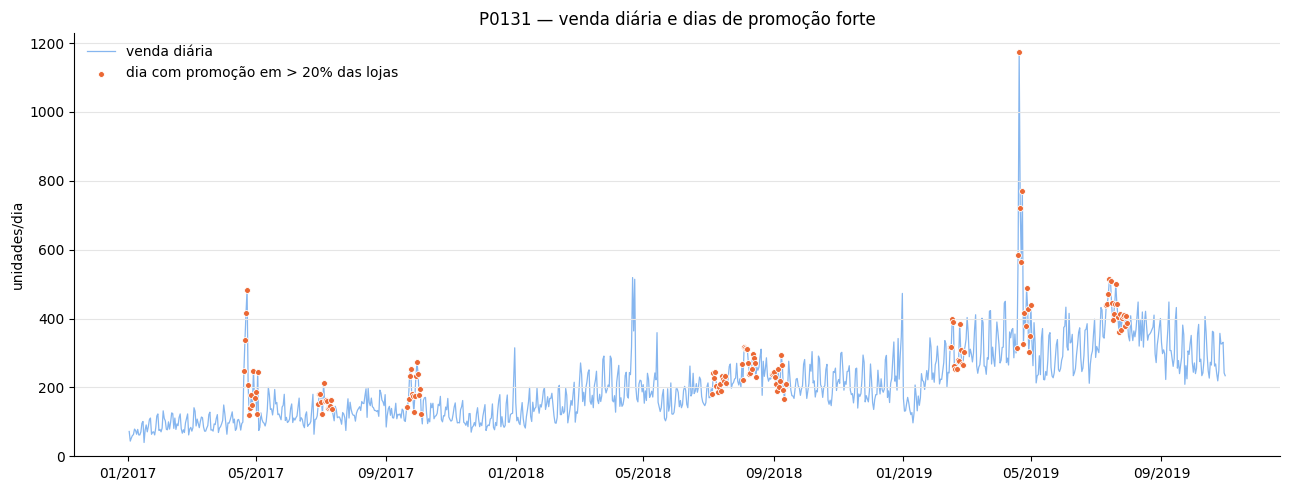

Dias por faixa de pct_lojas_promo:
pct_lojas_promo
até 2%          900
2% a 20%          0
acima de 20%    133

Períodos com promoção > 20% (início, fim, dias, pct médio):
    inicio        fim  dias  pct_medio
2017-04-20 2017-05-03    14      0.909
2017-06-29 2017-07-12    14      0.923
2017-09-21 2017-10-04    14      0.888
2018-07-05 2018-07-18    14      0.902
2018-08-02 2018-08-15    14      0.897
2018-08-30 2018-09-12    14      0.956
2019-02-14 2019-02-27    14      0.971
2019-04-18 2019-05-01    14      0.981
2019-07-11 2019-07-31    21      0.972


In [25]:
PRODUTOS_DESCONTINUADOS = ["P0438", "P0051", "P0079"]

promo = serie_p0131["pct_lojas_promo"]
dia_promo_forte = promo > 0.2
dia_sem_promo = promo <= 0.02

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(venda.index, venda.values, color="#86b6ef", lw=0.9, label="venda diária", zorder=1)
ax.scatter(venda.index[dia_promo_forte], venda[dia_promo_forte], color="#eb6834", s=18, zorder=2,
           edgecolor="white", linewidth=0.6, label="dia com promoção em > 20% das lojas")
ax.set_title(f"{PRODUTO} — venda diária e dias de promoção forte")
ax.set_ylabel("unidades/dia")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "02_P0131_promocao.png", dpi=130)
plt.show()

print("Dias por faixa de pct_lojas_promo:")
print(pd.cut(promo, [-0.001, 0.02, 0.2, 1.0], labels=["até 2%", "2% a 20%", "acima de 20%"]).value_counts().sort_index().to_string())
print("\nPeríodos com promoção > 20% (início, fim, dias, pct médio):")
blocos = (dia_promo_forte != dia_promo_forte.shift()).cumsum()[dia_promo_forte]
print(promo[dia_promo_forte].groupby(blocos).agg(inicio=lambda s: s.index.min().date(), fim=lambda s: s.index.max().date(),
                                                dias="size", pct_medio="mean").round(3).to_string(index=False))

In [26]:
media_promo = venda[dia_promo_forte].mean()
media_sem_promo = venda[dia_sem_promo].mean()
print(f"Venda média, promoção > 20% das lojas: {media_promo:.2f}  (n = {dia_promo_forte.sum()} dias)")
print(f"Venda média, promoção ≤ 2% das lojas:  {media_sem_promo:.2f}  (n = {dia_sem_promo.sum()} dias)")
print(f"Fator multiplicador bruto:             {media_promo / media_sem_promo:.3f}")

# checagem sem o efeito da tendência: venda dividida pela média móvel 28d centrada
relativa = venda / media_movel_28
print(f"\nVenda / média móvel 28d — promoção > 20%: {relativa[dia_promo_forte].mean():.3f} | ≤ 2%: {relativa[dia_sem_promo].mean():.3f}")
print(f"Fator multiplicador sem tendência:     {relativa[dia_promo_forte].mean() / relativa[dia_sem_promo].mean():.3f}")

top_residuos = residuo.nlargest(15).index
print(f"\nDos 15 maiores resíduos positivos da STL, {dia_promo_forte[top_residuos].sum()} caem em dia de promoção > 20%:")
print(pd.DataFrame({"residuo": residuo[top_residuos].round(1), "pct_lojas_promo": promo[top_residuos].round(3)}).to_string())
extremos_pos = residuo_padronizado > 3
print(f"\nDias com resíduo > 3 escalas robustas: {extremos_pos.sum()} | em promoção > 20%: {(extremos_pos & dia_promo_forte).sum()}")

Venda média, promoção > 20% das lojas: 290.62  (n = 133 dias)
Venda média, promoção ≤ 2% das lojas:  195.86  (n = 900 dias)
Fator multiplicador bruto:             1.484

Venda / média móvel 28d — promoção > 20%: 1.127 | ≤ 2%: 0.979
Fator multiplicador sem tendência:     1.152

Dos 15 maiores resíduos positivos da STL, 10 caem em dia de promoção > 20%:
            residuo  pct_lojas_promo
data                                
2019-04-20    682.8            1.000
2019-04-23    395.9            1.000
2017-04-23    328.6            0.911
2018-04-23    325.2            0.000
2018-12-31    297.7            0.000
2018-04-21    281.9            0.000
2019-04-21    258.7            1.000
2019-04-22    244.0            1.000
2017-04-22    222.7            0.879
2019-04-19    218.1            1.000
2017-04-21    209.8            0.928
2018-05-14    205.2            0.000
2019-06-03    164.6            0.000
2019-05-01    159.5            0.971
2017-05-03    139.3            0.904

Dias com resíduo

## 14. Fechamento da Fase 2 — achados e decisões

| # | Achado | Decisão |
|---|--------|---------|
| 1 | Grão loja × dia é intermitente: P0131 vende 1,64 un/dia por loja, mediana 0, 51,25% dos dias com venda zero (CV 2,70). Na rede: 208,06 un/dia, 0% de zeros (CV 0,51) | Prever no grão produto × dia na rede, com `demanda.csv`; `demanda_por_loja.csv` sai do projeto |
| 2 | STL robusta (período 7) do P0131: força da tendência 0,82 e da sazonalidade semanal 0,37; fim de semana vende 1,32× o dia útil | Modelos candidatos precisam tratar tendência e sazonalidade ao mesmo tempo, com período sazonal 7; baselines (média 4 semanas e naive sazonal) ficam só como régua de comparação |
| 3 | P0438, P0051 e P0079 em descontinuação: razão 90d / (455–90d) de 0,000; 0,108; 0,137, com séries que caem e ficam no chão | Filtro de ciclo de vida na Fase 3: os três saem do painel |
| 4 | Promoção (> 20% das lojas) multiplica a venda do P0131 por 1,48 (1,15 descontando a tendência), explica 10 dos 15 maiores resíduos da STL e é fechada 6–8 semanas antes, ou seja, já é conhecida no momento da decisão | `pct_lojas_promo` entra como variável exógena na Fase 4 |
| 5 | `unidades` é venda observada, censurada em dia de ruptura; `estoque_total` é saldo de fim de dia somado nas lojas, não o estoque do CD | Nenhuma ação agora; fica registrado como limitação para a Fase 6 |
